In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
import warnings

from scipy.stats import spearmanr
from itertools import combinations
from pathlib import Path
from __future__ import annotations
from types import SimpleNamespace
from mpl_toolkits.axes_grid1 import make_axes_locatable
warnings.filterwarnings("ignore", category=RuntimeWarning)

In [ ]:
MONTHS_RU = ["Янв","Фев","Мар","Апр","Май","Июн","Июл","Авг","Сен","Окт","Ноя","Дек"]
FIGSIZE = (13.33, 7.5)

def read_aligned(out_dir, param, date):
    p = Path(out_dir) / "aligned" / f"{param}_{date:%Y-%m-%d}.tif"
    if not p.exists():
        return None
    with rasterio.open(p) as s:
        return s.read(1)

def make_grid(out_dir):
    p = Path(out_dir) / "permanent_water_mask.tif"
    with rasterio.open(p) as s:
        return SimpleNamespace(crs=s.crs, transform=s.transform,
                               width=s.width, height=s.height)

def setup_style():
    plt.rcParams.update({"font.size": 16, "axes.titlesize": 21, "axes.titleweight": "bold",
                         "axes.labelsize": 16, "axes.spines.top": False, "axes.spines.right": False,
                         "axes.grid": True, "grid.alpha": 0.25, "legend.frameon": False,
                         "figure.dpi": 100})

def year_colors(years):
    cmap = plt.get_cmap("viridis"); ys = sorted(years)
    return {y: cmap(0.08 + 0.82 * i / max(1, len(ys) - 1)) for i, y in enumerate(ys)}


def fig_calendar(d, colors):
    fig, ax = plt.subplots(figsize=FIGSIZE)
    for y, g in d.groupby("year"):
        ax.scatter(g.doy, [y] * len(g), color=colors[y], s=260,
                   edgecolor="0.3", linewidth=0.8, zorder=3)
    months_show = [5, 6, 7, 8]
    starts = [pd.Timestamp(2001, m, 1).dayofyear for m in months_show]
    ax.set_xticks(starts, [MONTHS_RU[m - 1] for m in months_show])
    xmin = pd.Timestamp(2001, months_show[0], 1).dayofyear
    xmax = (pd.Timestamp(2001, months_show[-1], 1) + pd.offsets.MonthEnd(1)).dayofyear
    ax.set_xlim(xmin - 3, xmax + 3)
    ax.set_yticks(sorted(d.year.unique())); ax.invert_yaxis()
    ax.set_title("Календарь наблюдений: каждая точка — снимок Landsat")
    handles = [plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=colors[y],
                          markeredgecolor="0.3", markersize=12, label=str(y))
               for y in sorted(colors)]
    ax.legend(handles=handles, ncol=len(handles), loc="upper center",
              bbox_to_anchor=(0.5, -0.08), fontsize=10.5)
    fig.subplots_adjust(bottom=0.2)


def fig_channel_extremes_by_year(d, grid, cfg):
    dd = d[d.in_season & d.fai_mean.notna()]
    if dd.empty:
        return
    specs = {"FAI": ("FAI", "YlGn"), "T": ("Мутность (T)", "YlOrBr")}
    params = ["FAI", "T"]
    h, w = grid.height, grid.width
    step = max(1, max(h, w) // 1000)
    t = grid.transform
    extent = (t.c, t.c + t.a * w, t.f + t.e * h, t.f)

    for y, g in dd.groupby("year"):
        r_min = g.loc[g.fai_mean.idxmin()]
        r_max = g.loc[g.fai_mean.idxmax()]
        if r_min.date == r_max.date:
            dates = [("единственный снимок сезона", r_min.date, r_min.fai_mean)]
        else:
            dates = [("минимум среднего FAI", r_min.date, r_min.fai_mean),
                     ("максимум среднего FAI", r_max.date, r_max.fai_mean)]

        rasters = {}
        for _, date, _ in dates:
            for p in params:
                a = read_aligned(cfg.out_dir, p, date)
                if a is not None:
                    rasters[(p, date)] = a
        avail = [p for p in params if any((p, date) in rasters for _, date, _ in dates)]
        if not avail:
            continue

        ncols = len(dates)
        fig, axes = plt.subplots(len(avail), ncols, squeeze=False,
                                 figsize=(FIGSIZE[0] * 0.5 * ncols,
                                          FIGSIZE[0] * 0.5 * ncols / ncols * h / w * len(avail) + 1.8))
        for i, p in enumerate(avail):
            arrs = {date: rasters.get((p, date)) for _, date, _ in dates}
            fin = np.concatenate([a[np.isfinite(a)] for a in arrs.values() if a is not None]
                                 or [np.array([0.0, 1.0])])
            vmin, vmax = np.percentile(fin, [2, 98]) if fin.size else (0, 1)
            cmap = plt.get_cmap(specs[p][1]).copy(); cmap.set_bad("0.93")
            im = None
            for j, (label, date, faiv) in enumerate(dates):
                ax = axes[i, j]; a = arrs.get(date)
                if a is None:
                    ax.axis("off"); continue
                im = ax.imshow(np.ma.masked_invalid(a[::step, ::step]), cmap=cmap,
                               vmin=vmin, vmax=vmax, extent=extent, aspect="auto")
                if i == 0:
                    ax.set_title(f"{label}\n{date:%Y-%m-%d}  (FAI={faiv:.4f})", fontsize=12.5)
                if j == 0:
                    ax.set_ylabel(specs[p][0], fontsize=12.5)
                ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
            if im is not None:
                divider = make_axes_locatable(axes[i, -1])
                cax = divider.append_axes("right", size="6%", pad=0.18)
                fig.colorbar(im, cax=cax, aspect=25)
        fig.suptitle(f"Каналы на даты min/max среднего FAI, {y} год",
                     fontsize=19, fontweight="bold")
        fig.subplots_adjust(top=1 - 1.6 / fig.get_size_inches()[1], hspace=0.45)


def fig_channel_maps_period(chan_maps, grid, cfg):
    specs = {"FAI": ("FAI", "YlGn"), "T": ("Мутность (T)", "YlOrBr")}
    h, w = grid.height, grid.width
    step = max(1, max(h, w) // 1000)
    t = grid.transform
    extent = (t.c, t.c + t.a * w, t.f + t.e * h, t.f)
    for p in ("FAI", "T"):
        by_key = chan_maps.get(p)
        if not by_key or "all" not in by_key:
            continue
        arr = by_key["all"]
        if not np.isfinite(arr).any():
            continue
        fig, ax = plt.subplots(figsize=FIGSIZE)
        fin = arr[np.isfinite(arr)]
        vmin, vmax = np.percentile(fin, [2, 98]) if fin.size else (0, 1)
        cmap = plt.get_cmap(specs[p][1]).copy(); cmap.set_bad("0.93")
        im = ax.imshow(np.ma.masked_invalid(arr[::step, ::step]), cmap=cmap,
                       vmin=vmin, vmax=vmax, extent=extent, aspect="equal")
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        divider = make_axes_locatable(ax)
        cax = divider.append_axes("right", size="4%", pad=0.15)
        fig.colorbar(im, cax=cax, label=specs[p][0])
        ax.set_title(f"Пространственное распределение {specs[p][0]} "
                     f"(среднее за {cfg.years[0]}–{cfg.years[1]})")


def make_figures(df, chan_maps, grid, cfg):
    setup_style()
    d = df[df.use].sort_values("date")
    if d.empty:
        print("Нет пригодных сцен — графики не построены.")
        return
    colors = year_colors(d.year.unique())
    fig_calendar(d, colors)
    fig_channel_extremes_by_year(d, grid, cfg)
    fig_channel_maps_period(chan_maps, grid, cfg)

def main():
    cfg = SimpleNamespace(out_dir=Path(OUT_DIR), years=(2022, 2026))
    df = pd.read_csv(cfg.out_dir / "scene_stats.csv")
    df["date"] = pd.to_datetime(df["date"])
    grid = make_grid(cfg.out_dir)
    chan_maps = {}
    for p in ("FAI", "T"):
        f = cfg.out_dir / f"channel_mean_{p}_all.tif"
        if f.exists():
            with rasterio.open(f) as s:
                chan_maps[p] = {"all": s.read(1)}

    make_figures(df, chan_maps, grid, cfg)
    plt.show()

main()

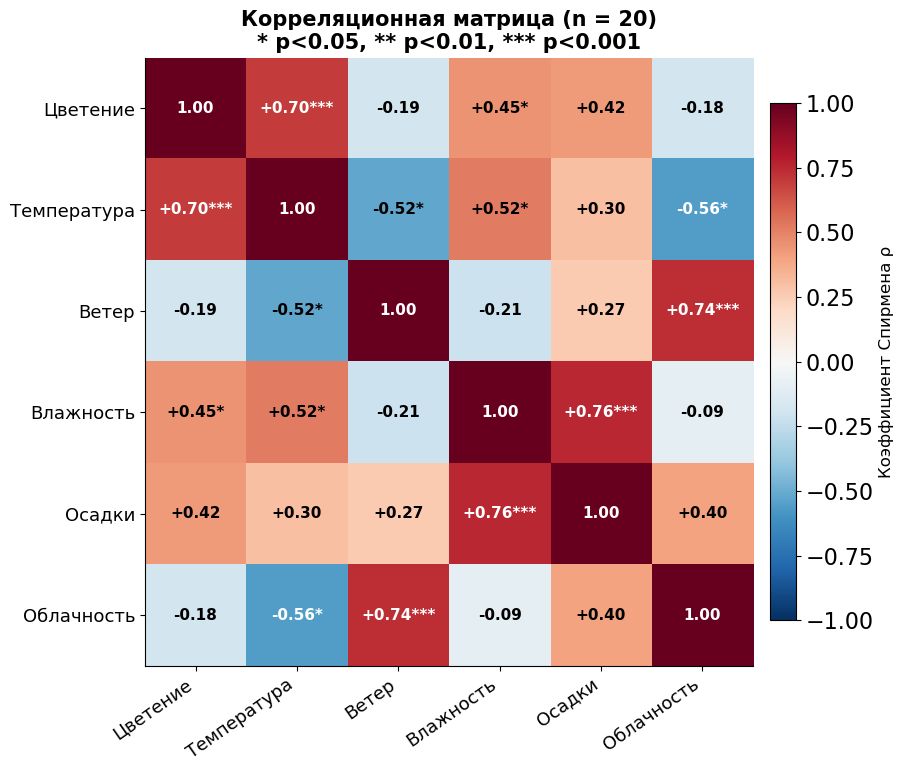

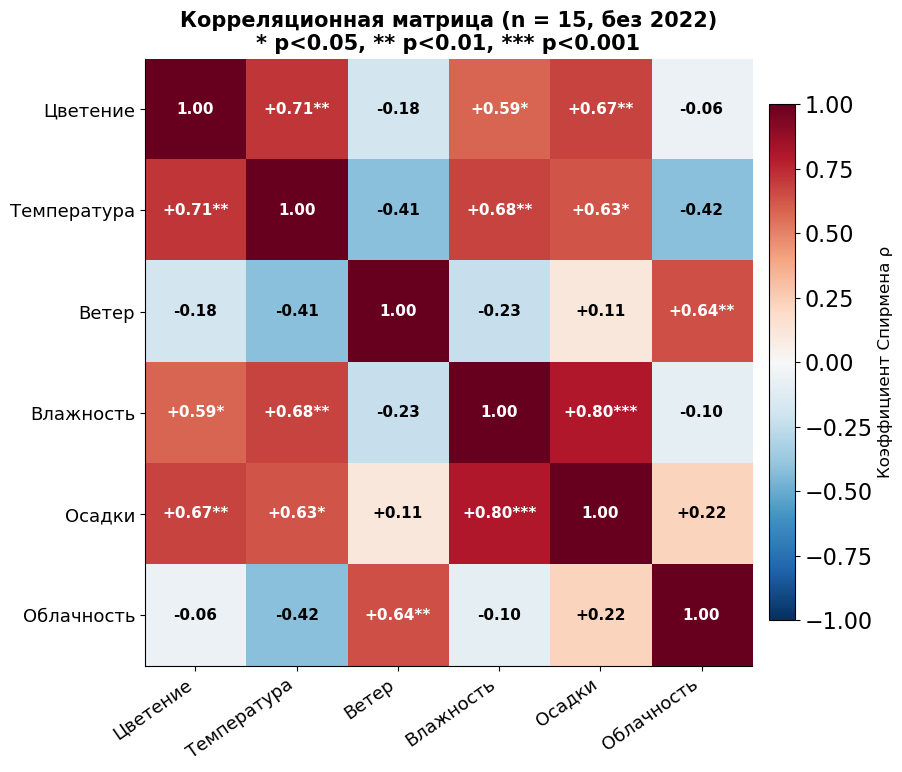

In [3]:
OUT_DIR = Path("results2")

df = pd.read_csv(OUT_DIR / "scene_stats_with_weather.csv")
df["date"] = pd.to_datetime(df["date"])
df["year"] = df["date"].dt.year


def plot_correlation_matrix(df, exclude_year=None):
    cols = ["bloom_frac", "temp_mean", "wind_speed_mean",
            "humidity_mean", "precip_sum", "cloud_cover_mean"]
    cols = [c for c in cols if c in df.columns and df[c].notna().sum() >= 5]

    d = df.copy()
    if exclude_year is not None:
        d = d[d.year != exclude_year]
    d = d[cols].dropna()
    n = len(d)

    labels_ru = {
        "bloom_frac": "Цветение",
        "temp_mean": "Температура",
        "wind_speed_mean": "Ветер",
        "humidity_mean": "Влажность",
        "precip_sum": "Осадки",
        "cloud_cover_mean": "Облачность",
    }
    short = [labels_ru.get(c, c) for c in cols]

    k = len(cols)
    rho = np.full((k, k), np.nan)
    pval = np.full((k, k), np.nan)
    for i, j in combinations(range(k), 2):
        r, p = spearmanr(d.iloc[:, i], d.iloc[:, j])
        rho[i, j] = rho[j, i] = r
        pval[i, j] = pval[j, i] = p
    np.fill_diagonal(rho, 1.0)

    fig, ax = plt.subplots(figsize=(10, 8))
    cmap = plt.get_cmap("RdBu_r").copy()
    cmap.set_bad("0.9")
    im = ax.imshow(np.ma.masked_invalid(rho), cmap=cmap, vmin=-1, vmax=1)

    ax.set_xticks(range(k), short, rotation=35, ha="right", fontsize=13)
    ax.set_yticks(range(k), short, fontsize=13)
    ax.grid(False)

    for i in range(k):
        for j in range(k):
            if i == j:
                txt, col = "1.00", "white"
            elif np.isnan(rho[i, j]):
                txt, col = "–", "0.5"
            else:
                r = rho[i, j]
                p = pval[i, j]
                if p < 0.001:
                    star = "***"
                elif p < 0.01:
                    star = "**"
                elif p < 0.05:
                    star = "*"
                else:
                    star = ""
                txt = f"{r:+.2f}{star}"
                col = "white" if abs(r) > 0.55 else "black"
            ax.text(j, i, txt, ha="center", va="center",
                    color=col, fontsize=11, fontweight="bold")

    cb = fig.colorbar(im, ax=ax, shrink=0.85, pad=0.02)
    cb.set_label("Коэффициент Спирмена ρ", fontsize=12)
    title = f"Корреляционная матрица (n = {n}"
    if exclude_year:
        title += f", без {exclude_year}"
    title += ")"
    ax.set_title(title + "\n* p<0.05, ** p<0.01, *** p<0.001",
                 fontsize=15, fontweight="bold")
    fig.tight_layout()

    print(f"\nКорреляционная матрица (n = {n}"
          + (f", без {exclude_year}" if exclude_year else "") + "):")
    for i, j in combinations(range(k), 2):
        print(f"  {short[i]:<14} ↔ {short[j]:<14}: "
              f"ρ = {rho[i,j]:+.3f}, p = {pval[i,j]:.4f}")
    return rho, pval


plot_correlation_matrix(df)
plot_correlation_matrix(df, exclude_year=2022)

plt.show()